<a href="https://colab.research.google.com/github/Rigtsu/image_processing/blob/main/hw4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math

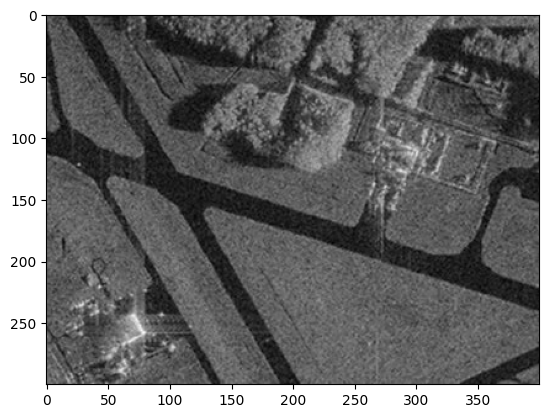

In [ ]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [ ]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False


In [ ]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r + 1, j-r: j+r+1].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        #print(count)
        mask += local_mask

    return mask*255

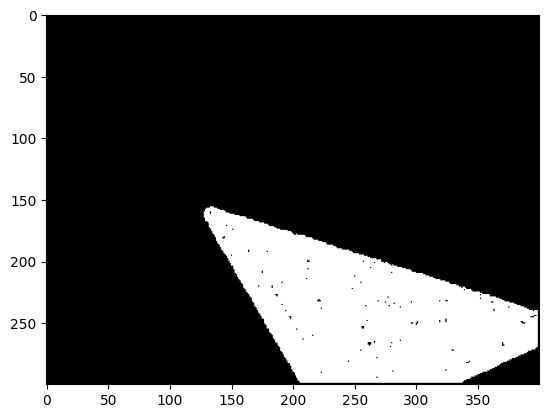

In [6]:
seed_point = (200,225)
mask = region_growing(image_gray,seed_point,homo_average,1, 25)
plt.imshow(mask, cmap="gray")

Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

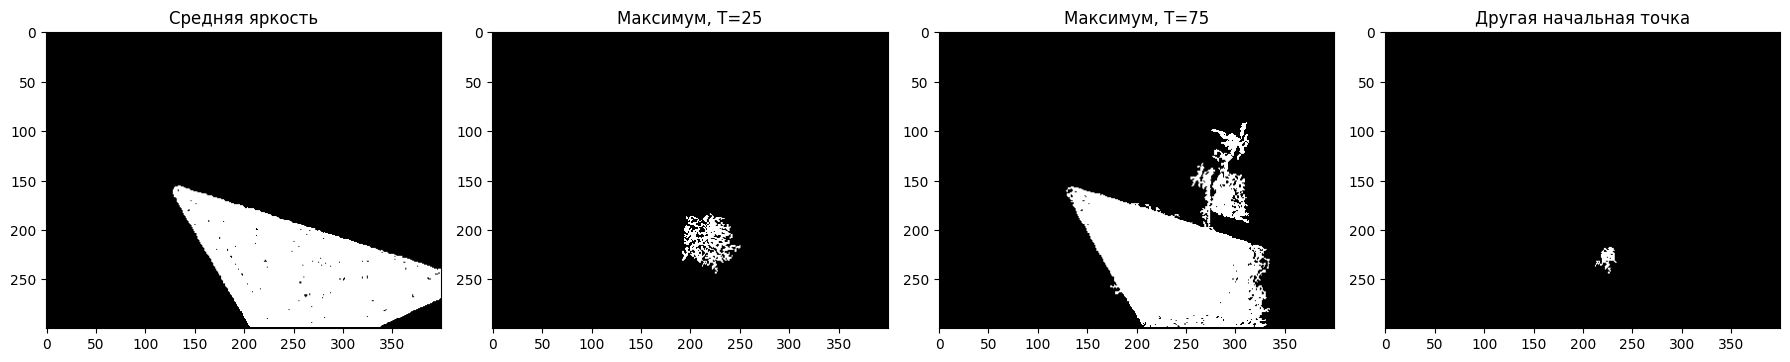

In [16]:
def homo_max(img, mask, point, threshold):
    max_value = np.max(img[mask != 0])
    return abs(float(max_value) - float(img[point])) <= threshold


mask_max_25 = region_growing(image_gray, (200, 225), homo_max, 1, 25)
mask_max_75 = region_growing(image_gray, (200, 225), homo_max, 1, 75)
mask_max_other_seed = region_growing(image_gray, (225, 225), homo_max, 1, 25)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
results = [mask, mask_max_25, mask_max_75, mask_max_other_seed]
titles = ['Средняя яркость', 'Максимум, T=25', 'Максимум, T=75', 'Другая начальная точка']
for ax, result, title in zip(axes, results, titles):
    ax.imshow(result, cmap='gray')
    ax.set_title(title)
plt.tight_layout()

Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

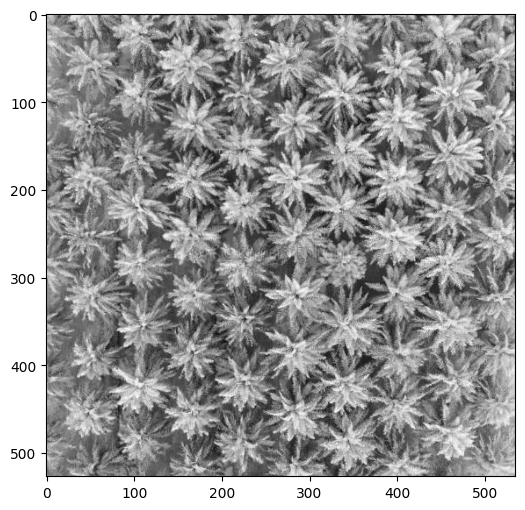

In [17]:
palm_image = cv2.imread('palm_1.jpg')
palm_gray = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(9, 6))
plt.imshow(palm_gray, cmap='gray')

Пальм = 84


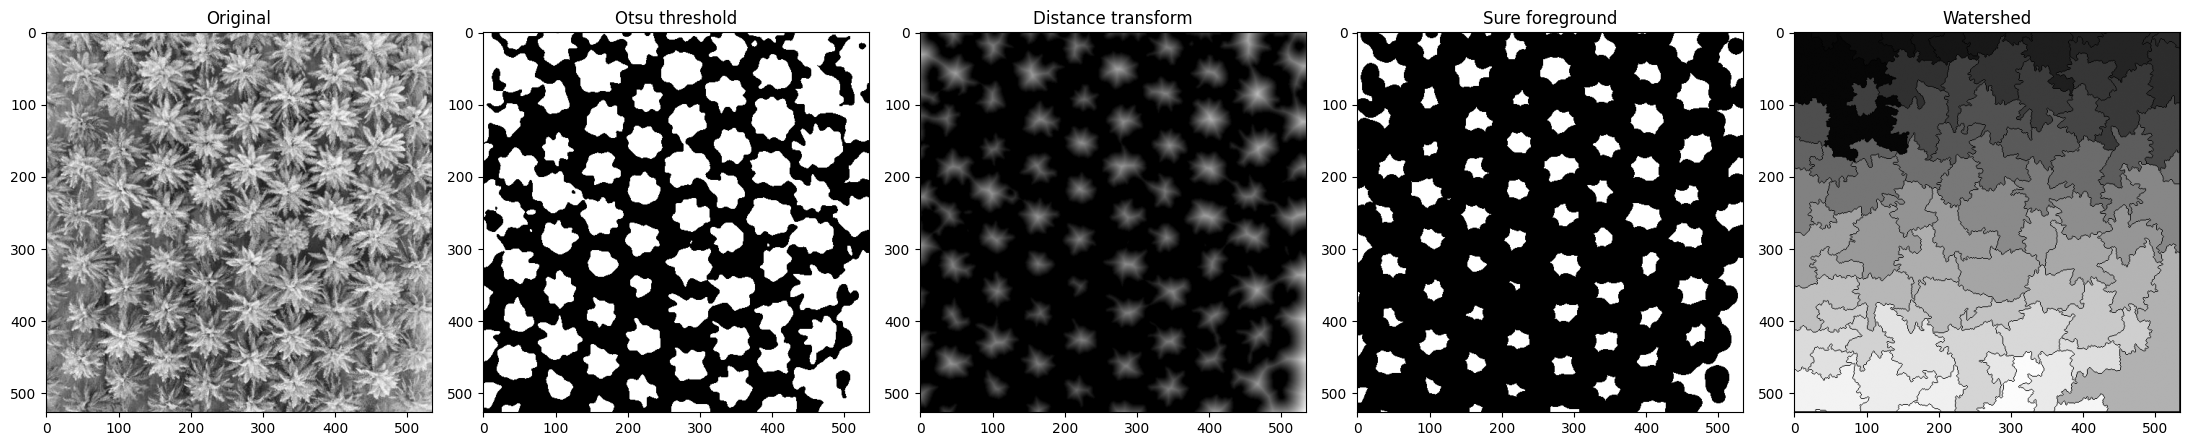

In [18]:
image_palm_blur = cv2.GaussianBlur(palm_gray, (25, 25), 0)

ret, thresh_palm = cv2.threshold(image_palm_blur, 0, 255,cv2.THRESH_BINARY + cv2.THRESH_OTSU)

dist_palm = cv2.distanceTransform(thresh_palm, cv2.DIST_L2, 5)

ret, sure_fg_palm = cv2.threshold(dist_palm, 0.2 * dist_palm.max(), 255,cv2.THRESH_BINARY)

sure_fg_palm = sure_fg_palm.astype(np.uint8)

ret, markers_palm = cv2.connectedComponents(sure_fg_palm)

num_palms = ret - 1
print(f"Пальм = {num_palms}")

markers_palm = cv2.watershed(palm_image, markers_palm)


fig, axes = plt.subplots(1, 5, figsize=(22, 5))

results = [
    (palm_gray, 'Original'),
    (thresh_palm, 'Otsu threshold'),
    (dist_palm, 'Distance transform'),
    (sure_fg_palm, 'Sure foreground'),
    (markers_palm, 'Watershed')
]

for ax, (img, title) in zip(axes, results):
    ax.imshow(img, cmap='gray')
    ax.set_title(title)

plt.tight_layout()
plt.show()